Estes es un Notebook ejemplo que tiene como objetivo mostrar el funcionamiento de diferentes metodos para seleccion de atributos. Este ejemplo es una modificacion de los ejemplos disponibles en https://github.com/Yimeng-Zhang/feature-engineering-and-feature-selection desarrollados por Yimeng-Zhang. Esta modificacion y adaptacion de los ejemplos origniales ha sido elaborada para el curso de inteligencia artificial del programa de Ingenieria de Sistemas de la Universidad del Magdalena.  

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
#import matplotlib as plt
import os
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.linear_model import Lasso, LogisticRegression

from sklearn.feature_selection import SelectFromModel
#from feature_selection import embedded_method

## Load Dataset

In [2]:
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer()
data = pd.DataFrame(np.c_[data['data'], data['target']],
                  columns= np.append(data['feature_names'], ['target']))

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

El dataset está conformado por 569 ejemplos de casos de cancer de mama positivos y negativos, de los cuales se cuenta con 30 variables predictoras y la variable a predecir la cual es target. Todas las variables predictoras son de tipo numérico, continuas. La variable a predecir es de tipo binario. 

In [4]:
data.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


Todas las variables predictoras son de tipo numérico, continuas, que toman valores en diferentes rangos de valores. Estas variables son caracteristicas estimadas a partir de imagenes digitalizadas de aspiraciones con aguja fina (FNA) de masas de mama. Spm caracteristicas de los núcleos celulares presentes en las imágenes.

# Inspección de los datos

## Inspección de datos nulos

In [5]:
data.isna().sum() #Para observar si hay datos nulos en el dataset

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

## Distribución de las clases

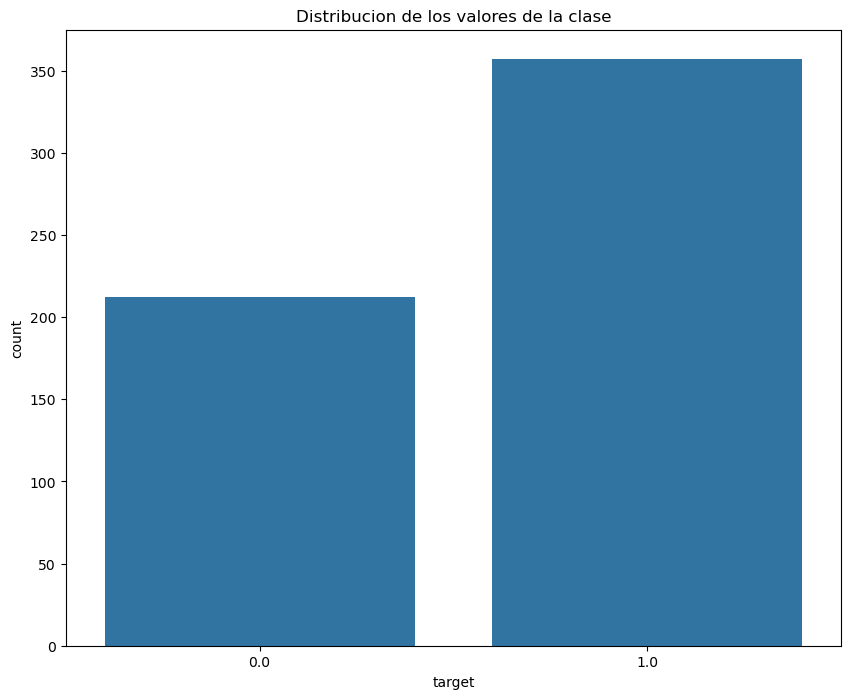

In [6]:
ax=plt.subplots(1,1,figsize=(10,8))
sns.countplot(x = "target", data=data)
plt.title("Distribucion de los valores de la clase")
plt.show()

Este diagrama de barras muestra la distribución de los ejemplos en las dos clases que contiene el dataset. Hay una diferencia en el número de ejemplos; pero la diferencia no es mucha. Se puede decir que el dataset cuenta con ejemplos de cada clase.

## Distribución de las variables predictoras

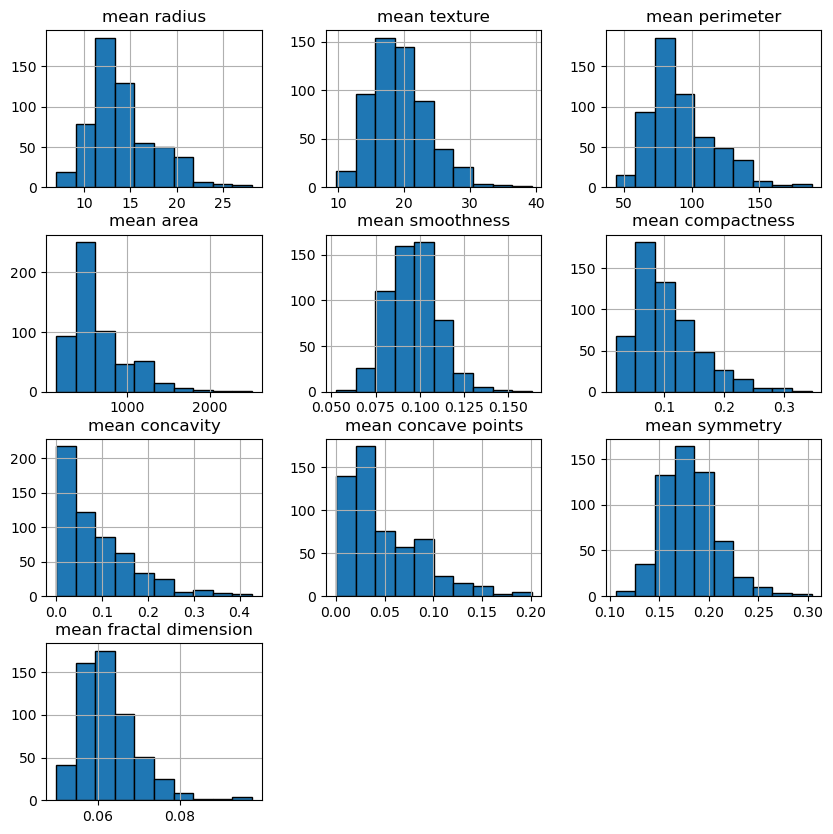

In [7]:
data.hist(['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 
           'mean compactness', 'mean concavity','mean concave points', 'mean symmetry', 
           'mean fractal dimension'],edgecolor='black', linewidth=1.0)
fig=plt.gcf()
fig.set_size_inches(10,10)
plt.show()

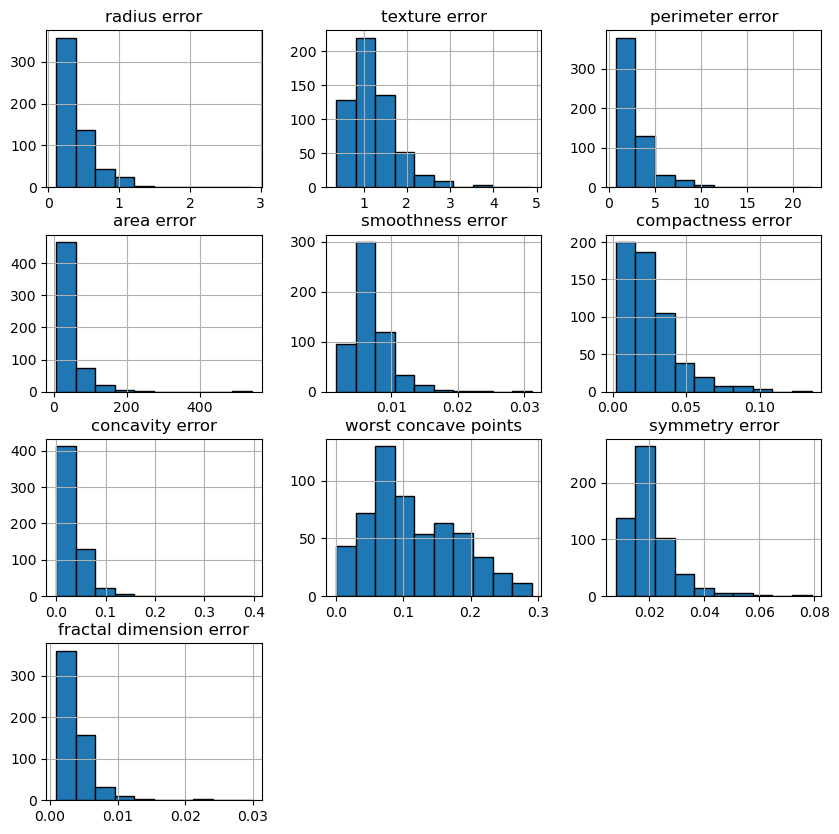

In [8]:
data.hist(['radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 
           'compactness error', 'concavity error','worst concave points', 'symmetry error', 
           'fractal dimension error'],edgecolor='black', linewidth=1.0)
fig=plt.gcf()
fig.set_size_inches(10,10)
plt.show()

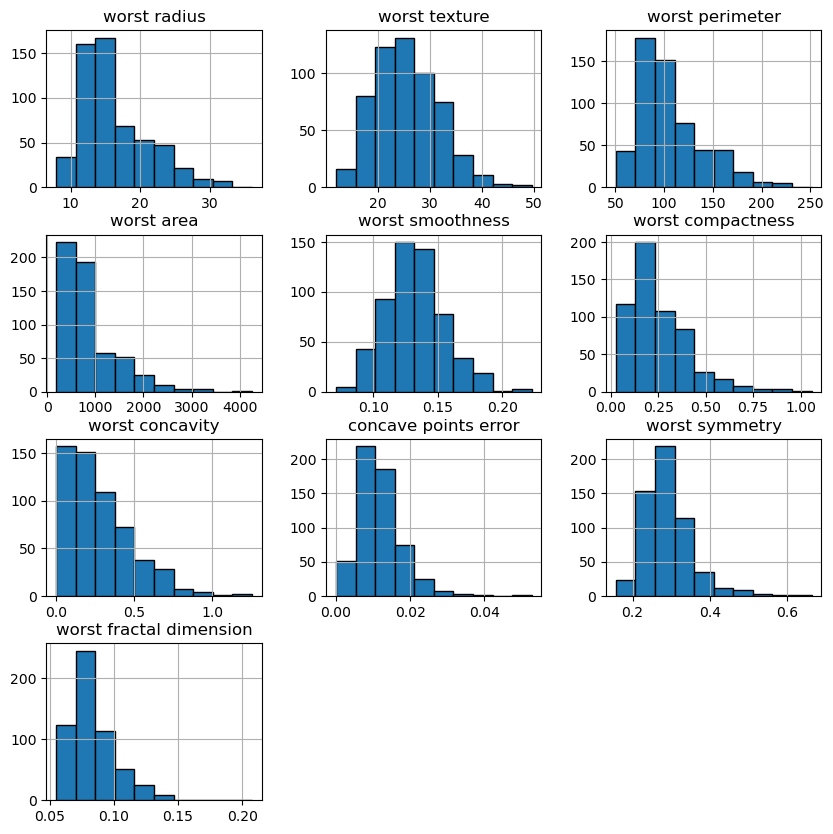

In [9]:
data.hist(['worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 
           'worst compactness', 'worst concavity','concave points error', 'worst symmetry', 
           'worst fractal dimension'],edgecolor='black', linewidth=1.0)
fig=plt.gcf()
fig.set_size_inches(10,10)
plt.show()

Muchas de las variables del estudio no muestran una distribución normal. Una distribución normal es simétrica y en forma de campana (la media ≈ mediana ≈ moda). En estas gráficas algunas distribuciones son altamente asimétricas, y no presentan forma de campana; por lo tanto se debe considerar el uso de estadísticos no paramétricos para su tratamiento. 

## Inspección de variables predictoras correlacionadas

In [10]:
X = data.drop(['target'], axis=1) # Separa las variables predictoras de las variable a predecir
y = data['target']

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

Entrenamiento: (455, 30)
Prueba: (114, 30)


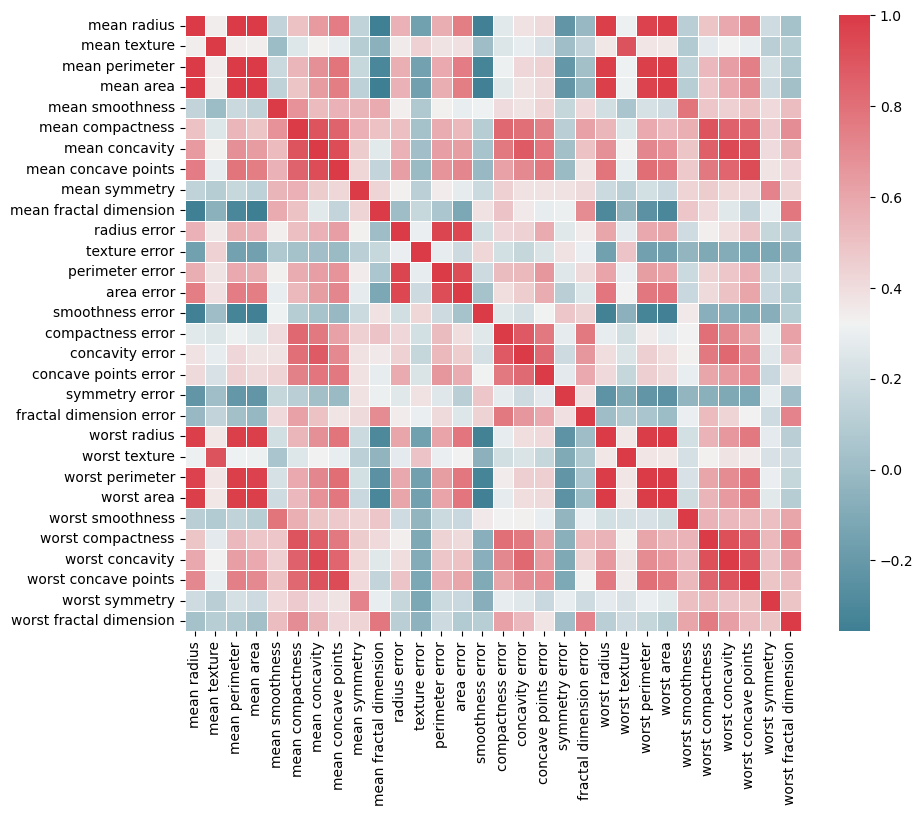

In [12]:
f, ax = plt.subplots(figsize=(10, 8))
corr = X_train.corr('spearman')
sns.heatmap(corr, mask=np.zeros_like(corr, dtype=bool), cmap=sns.diverging_palette(220, 10, as_cmap=True),square=True, ax=ax, linewidths=.5)
plt.show() 

In [13]:
# Matrices de correlación
corr_spearman = X_train.corr(method='spearman')

# Conservar únicamente el triángulo superior
mask = np.triu(np.ones(corr_spearman.shape), k=1).astype(bool)

# Construir tabla comparativa
pares = pd.DataFrame({'Spearman': corr_spearman.where(mask).stack()}).reset_index()

pares.columns = ['Variable 1', 'Variable 2', 'Spearman']

# Identificar parejas con correlación alta según Spearman
threshold = 0.95

pares_altos = pares[pares['Spearman'].abs() >= threshold].sort_values('Spearman', key=abs, ascending=False)

display(pares_altos.round(3))

,Variable 1,Variable 2,Spearman
2,mean radius,mean area,1.000
392,worst radius,worst area,0.999
1,mean radius,mean perimeter,0.998
57,mean perimeter,mean area,0.997
391,worst radius,worst perimeter,0.994
407,worst perimeter,worst area,0.992
74,mean perimeter,worst radius,0.982
77,mean perimeter,worst area,0.982
103,mean area,worst area,0.981
22,mean radius,worst area,0.980


En este resultado se puede observar que tres variables están fuertemente correlacionadas con otras variables del estudio, vamos a analizarcon más detalles estás tres variables con gráficas de dispersión.

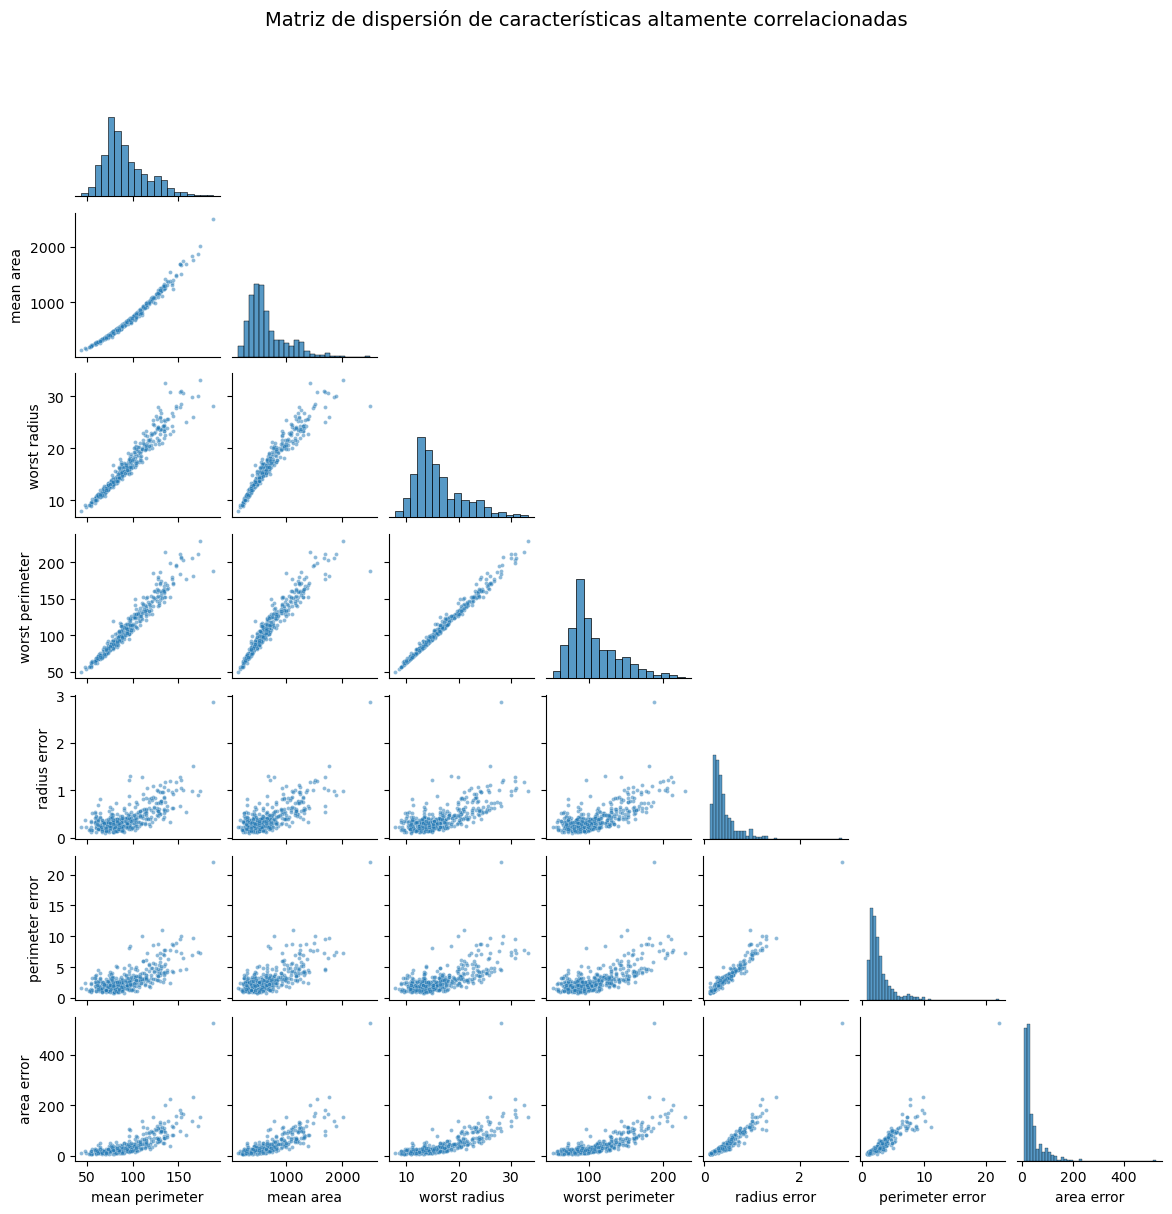

In [14]:
from pandas.plotting import scatter_matrix

variables_corr = ['mean perimeter', 'mean area',
                  'worst radius',   'worst perimeter',
                  'radius error',   'perimeter error',
                  'area error']

g = sns.pairplot(X_train[variables_corr], corner=True, diag_kind='hist', plot_kws={'alpha': 0.5, 's': 8}, height=1.7)

g.figure.suptitle("Matriz de dispersión de características altamente correlacionadas", y=1.02, fontsize=14)

#lt.tight_layout()
plt.show()

De acuerdo con la gráfica la variable mean area muestra una relación monótona positiva con la variable mean perimeter.  Las variables worst perimeter con worst radius también muestran una fuerte relación entre ellas. Se puede tomar la decisión de eliminar alguna de estas variables; sin embargo, vamos a aplicar diferentes filtros de carecterísticas para tomar la mejor decisión. 

# Seleccion de caracteristica - Filter

## Filtro basado en correlación


Vamos a crear un ranking de la correlación de las variables predictoras según su relación con la variable a predecir, utilizamos el coeficiente de Spearman debido a que algunas variables del estudio podrían no tener una distribución normal.

In [15]:
corr_matrix = data.corr(method='spearman')
corr_matrix = corr_matrix.abs().unstack()
corr_matrix['target'].sort_values(ascending=False)   

target                     1.000000
worst perimeter            0.796319
worst radius               0.787933
worst area                 0.786902
worst concave points       0.781674
mean concave points        0.777877
mean perimeter             0.748496
mean area                  0.734122
mean concavity             0.733308
mean radius                0.732785
area error                 0.714184
worst concavity            0.705734
perimeter error            0.630411
radius error               0.616912
mean compactness           0.609288
worst compactness          0.606810
concave points error       0.488717
worst texture              0.476720
concavity error            0.470338
mean texture               0.461971
worst smoothness           0.425513
worst symmetry             0.396843
compactness error          0.380666
mean smoothness            0.371892
mean symmetry              0.332567
worst fractal dimension    0.311477
fractal dimension error    0.201492
symmetry error             0

Al calcular la correlación de Spearman entre cada característica y la variable objetivo (target), se observó que worst perimeter (0.7963), worst radius (0.7879) y worst area (0.7869) presentan las mayores asociaciones absolutas. Sin embargo, algunas de estas características también están fuertemente correlacionadas entre sí.

## Filtro basado en el estadístico Chi_square

Se implementa un método de selección de características basado en el estadístico Chi-cuadrado (χ²). Primero, KBinsDiscretizer transforma las características numéricas continuas en cinco intervalos (n_bins=5) y utiliza codificación one-hot para representar cada intervalo mediante una variable binaria. Posteriormente, SelectKBest(chi2, k=10) configura un selector que identifica las diez características con las mayores puntuaciones del estadístico Chi-cuadrado, utilizado para evaluar su asociación con la variable objetivo. Finalmente, fit() calcula estas puntuaciones utilizando los datos de entrenamiento y fit.scores_ devuelve el valor del estadístico para cada característica.

In [16]:
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.feature_selection import SelectKBest, chi2

In [17]:
discretizador = KBinsDiscretizer(n_bins=5, encode='onehot', strategy='quantile')

X_binned = discretizador.fit_transform(X_train)

# Aplicar selección mediante Chi-cuadrado
X_selected = SelectKBest(chi2, k=10)
fit = X_selected.fit(X_binned, y_train)
fit.scores_

array([5.11346749e+01, 3.42306502e+01, 1.20206398e+01, 1.87822497e+01,
       1.47252838e+02, 3.68132095e+01, 1.31244639e+01, 6.48360031e-03,
       1.87822497e+01, 2.93472652e+01, 5.42807018e+01, 3.68132095e+01,
       1.35701754e+01, 2.48395253e+01, 1.47252838e+02, 4.80825593e+01,
       3.68132095e+01, 1.20206398e+01, 1.87822497e+01, 1.47252838e+02,
       2.48395253e+01, 7.93550052e+00, 1.17389061e+00, 2.30082559e+00,
       2.70464396e+01, 4.22600619e+01, 2.48395253e+01, 6.76160991e+00,
       1.87822497e+01, 9.50851393e+01, 5.42807018e+01, 3.68132095e+01,
       1.69509804e+01, 4.22600619e+01, 1.22131579e+02, 5.42807018e+01,
       4.51243550e+01, 2.27265222e+01, 4.22600619e+01, 1.52558824e+02,
       1.87822497e+01, 1.26821407e+01, 1.26770754e+00, 2.30082559e+00,
       2.70464396e+01, 6.76160991e+00, 6.76160991e+00, 0.00000000e+00,
       2.30082559e+00, 2.30082559e+00, 3.94896801e+01, 2.27265222e+01,
       5.68163055e+00, 7.93550052e+00, 1.12740454e+02, 3.00515996e+00,
      

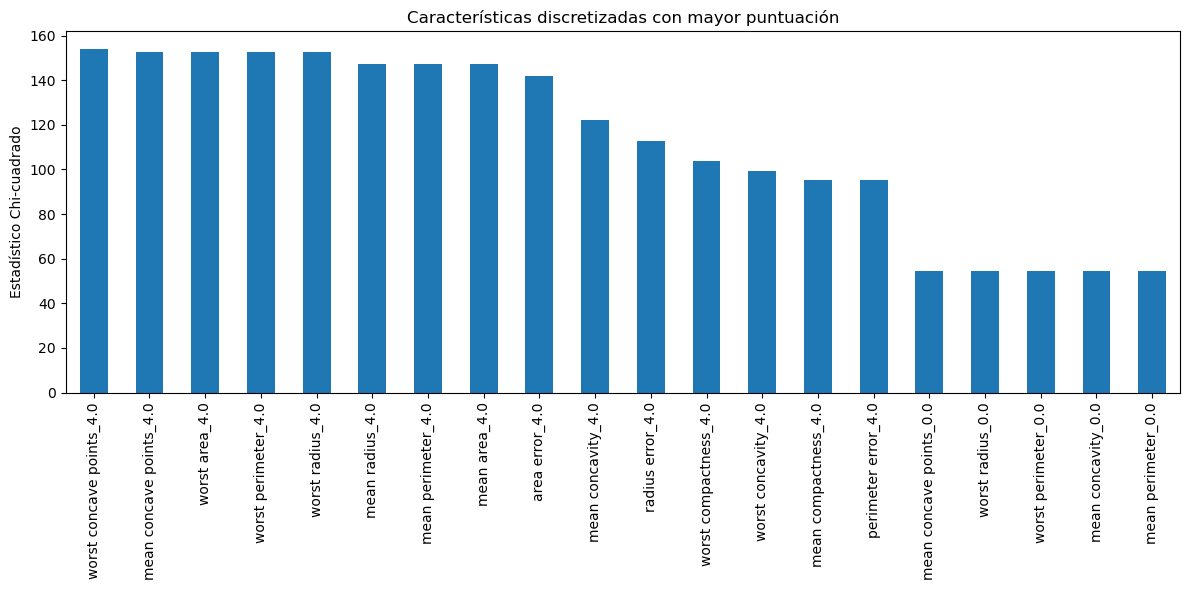

In [18]:
# Obtener nombres de las características discretizadas
nombres = discretizador.get_feature_names_out(X_train.columns)

# Crear una serie con las puntuaciones de Chi-cuadrado
chi_scores = pd.Series(fit.scores_, index=nombres)

# Ordenar y representar las 20 puntuaciones más altas
chi_scores = chi_scores.sort_values(ascending=False)

plt.figure(figsize=(12, 6))
chi_scores.head(20).plot.bar()
plt.ylabel("Estadístico Chi-cuadrado")
plt.title("Características discretizadas con mayor puntuación")
plt.tight_layout()
plt.show()

Podemos observar una coincidencia importante: las características que mostraron mayor asociación absoluta con target mediante Spearman también aparecen representadas entre los intervalos con mayores puntuaciones de Chi-cuadrado.

# Seleccion de caracteristicas - Wrapped

### Utilizando mlxtend

In [19]:
from mlxtend.feature_selection import SequentialFeatureSelector as SFS
from sklearn.tree import DecisionTreeClassifier

In [20]:
# Clasificador base
dt = DecisionTreeClassifier(max_depth=30, random_state=42)
valores_k = [5, 10, 15]

In [21]:
resultados = []
for k in valores_k:

    sfs = SFS(estimator=dt, k_features=k, forward=True, floating=False, scoring='accuracy', cv=0)
    sfs.fit(X_train, y_train)

    resultados.append({'k': k, 'Accuracy': sfs.k_score_, 'Características': list(sfs.k_feature_names_)})

resultados_sfs = pd.DataFrame(resultados)
pd.set_option('display.max_colwidth', None)
display(resultados_sfs)

,k,Accuracy,Características
0,5,1.0,"[mean radius, mean texture, mean perimeter, mean area, mean concave points]"
1,10,1.0,"[mean radius, mean texture, mean perimeter, mean area, mean smoothness, mean compactness, mean concavity, mean concave points, mean symmetry, mean fractal dimension]"
2,15,1.0,"[mean radius, mean texture, mean perimeter, mean area, mean smoothness, mean compactness, mean concavity, mean concave points, mean symmetry, mean fractal dimension, radius error, texture error, perimeter error, area error, smoothness error]"


MLxtend es una librería que implementa varios algoritmos útiles para ML y data mining. Entre ellos sequential feature selection (SFS) el cual es un algoritmo condicioso que busca un subconjunto óptimo de características iterativamente. Otra alternativa es utilizar la misma función SequentialFeatureSelector de la libreria Sickit-learn. A pesar de ser la misma función que internamente utiliza una algoritmo codicioso, se puede obtener resultados diferentes con las dos alternativas. 

# Seleccion de caracteristicas - Embedded

Aplicando regresión como método de clasificación se va a utilizar Lasso; como este es un método que utiliza el descenso por el gradiente para encontrar los parámetros del modelo, entoces se debe escalar los datos. 

## Lasso

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

modelo_l1 = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectFromModel(
        LogisticRegression(
            penalty='l1',
            C=0.1,
            solver='liblinear',
            max_iter=5000,
            random_state=42
        )
    )),
    ('classifier', LogisticRegression(
        solver='liblinear',
        max_iter=5000,
        random_state=42
    ))
])


modelo_l1.fit(X_train, y_train)

features_l1 = X_train.columns[modelo_l1.named_steps['selector'].get_support()]

print("Características seleccionadas:")
print(features_l1.tolist())

Características seleccionadas:
['mean texture', 'mean concave points', 'radius error', 'worst radius', 'worst texture', 'worst smoothness', 'worst concave points', 'worst symmetry']


In [23]:
coeficientes = modelo_l1.named_steps['selector'].estimator_.coef_[0]
print("Características con coeficiente cero:", X_train.columns[np.isclose(coeficientes, 0)].tolist())

Características con coeficiente cero: ['mean radius', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean symmetry', 'mean fractal dimension', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst perimeter', 'worst area', 'worst compactness', 'worst concavity', 'worst fractal dimension']


In [24]:
print("Accuracy entrenamiento:", modelo_l1.score(X_train, y_train))

Accuracy entrenamiento: 0.978021978021978


El método mismo durante el entrenamiento forza al procedimiento de optimización llevar algunos coeficientes o parámetros del modelo a 0, de esta forma algunas variables son eliminadas del modelo. 

## Random Forest Importance

In [25]:
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [26]:
# select features whose importance > threshold
feature_selection = SelectFromModel(clf, threshold=0.05, prefit=True) 
selected_feat = X_train.columns[(feature_selection.get_support())]
selected_feat

Index(['mean radius', 'mean perimeter', 'mean concavity',
       'mean concave points', 'worst radius', 'worst perimeter', 'worst area',
       'worst concave points'],
      dtype='object')

In [27]:
#Selecciona features cuya importancia es mayor a la mediana de los resultados
feature_selection2 = SelectFromModel(clf, threshold='median',prefit=True) 
selected_feat2 = X_train.columns[(feature_selection2.get_support())]
print('total features: {}'.format((X_train.shape[1])))
print('selected features: {}'.format(len(selected_feat2)))
print(selected_feat2)

total features: 30
selected features: 15
Index(['mean radius', 'mean perimeter', 'mean area', 'mean concavity',
       'mean concave points', 'radius error', 'area error', 'worst radius',
       'worst texture', 'worst perimeter', 'worst area', 'worst smoothness',
       'worst compactness', 'worst concavity', 'worst concave points'],
      dtype='object')


En este caso Random Forest es utilizado para construir un ranking de variables, entre más veces en todo el proceso de creación de los arboles que conforman el clasificador una variable es selecionada para particionar, más valor va adquiriendo en el ranking. Luego se seleccionan las variables cuyo valor en el ranking es mayor que 0.05, lo que da como resultado solo seis variables del estudio. Adicionalmente, de manera ilustrativa en lugar de 0.05, se especifica utilizar la mediana del ranking como umbral de selección, con lo cual, como se puede obeservar 15 características son seleccionadas. 

## Análisis final de los resultaodos

Los métodos de selección de características aplicados permitieron identificar diferentes subconjuntos de variables potencialmente relevantes para clasificar los casos del dataset. Algunas de las características mejor posicionadas presentan correlaciones muy elevadas entre sí, como ocurre con las variables relacionadas con el radio, perímetro y área. Como siguiente paso, se debería comparar el desempeño de un mismo clasificador utilizando todas las características y los subconjuntos obtenidos mediante los distintos métodos de selección. Esta evaluación debe realizarse sobre datos no utilizados durante el entrenamiento ni la selección, considerando tanto las métricas de clasificación como el número de características conservadas. Si varios subconjuntos presentan desempeños comparables, puede preferirse aquel que utilice menos características, favorezca la interpretabilidad y reduzca la redundancia.